# Solutions: Chapter 16, Statistical Charts with seaborn

Worked solutions to the exercises at the end of Chapter 16 of *Python for Data Science* by Vamsi Krishna Kandala. Try each exercise on your own first. Run the code yourself with the notebook [`ch16_solutions.ipynb`](ch16_solutions.ipynb) or the script `ch16_solutions.py`.

Numbers that depend on random data or library versions may differ slightly on your computer; the conclusions should not.


In [ ]:
# Setup: recreates the context these solutions build on (from the chapter).
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")
penguins = pd.read_csv("data/penguins.csv")
gap = pd.read_csv("data/gapminder.csv")
orders = pd.read_parquet("data/shop_orders.parquet")
orders = orders[orders["status"] != "cancelled"].assign(
    revenue=lambda d: d["quantity"] * d["unit_price"])

The solutions use the chapter's theme and the penguin, Gapminder and coffee-shop data, with a `revenue` column on the orders.

## Exercise 16.1

*Draw a histogram of the penguins' bill length with `hue="sex"` and `element="step"`, and say what the two outlines show.*

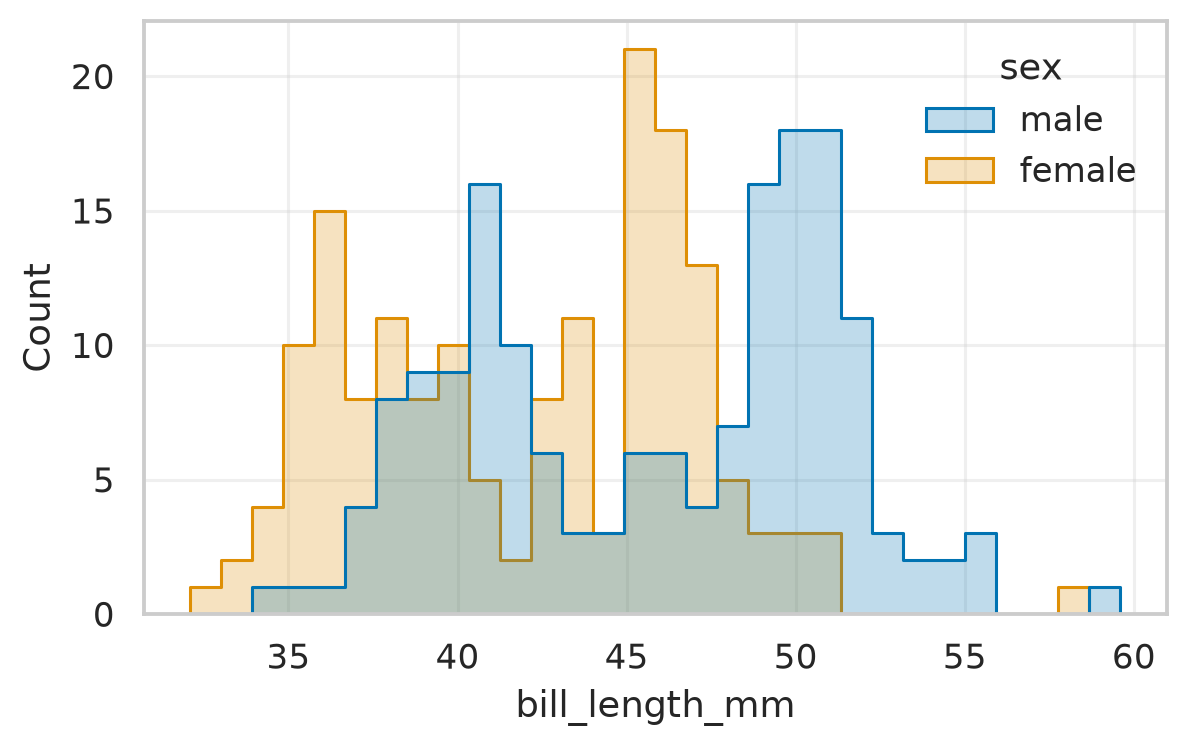

In [ ]:
sns.histplot(data=penguins, x="bill_length_mm", hue="sex",
             element="step", bins=30)
plt.show()

*Bill length by sex, as two outlined histograms.*

Both outlines have two or three peaks, because each mixes three species: Adelies with short bills, and Chinstraps and Gentoos with long ones. The male outline sits a few millimeters to the right of the female one throughout. Splitting by sex alone can't separate the species, which is why the chapter's charts split by both.

## Exercise 16.2

*Draw box plots of the coffee shop's order revenue by bag size. Which orders lie far above the 1-kilogram box?*

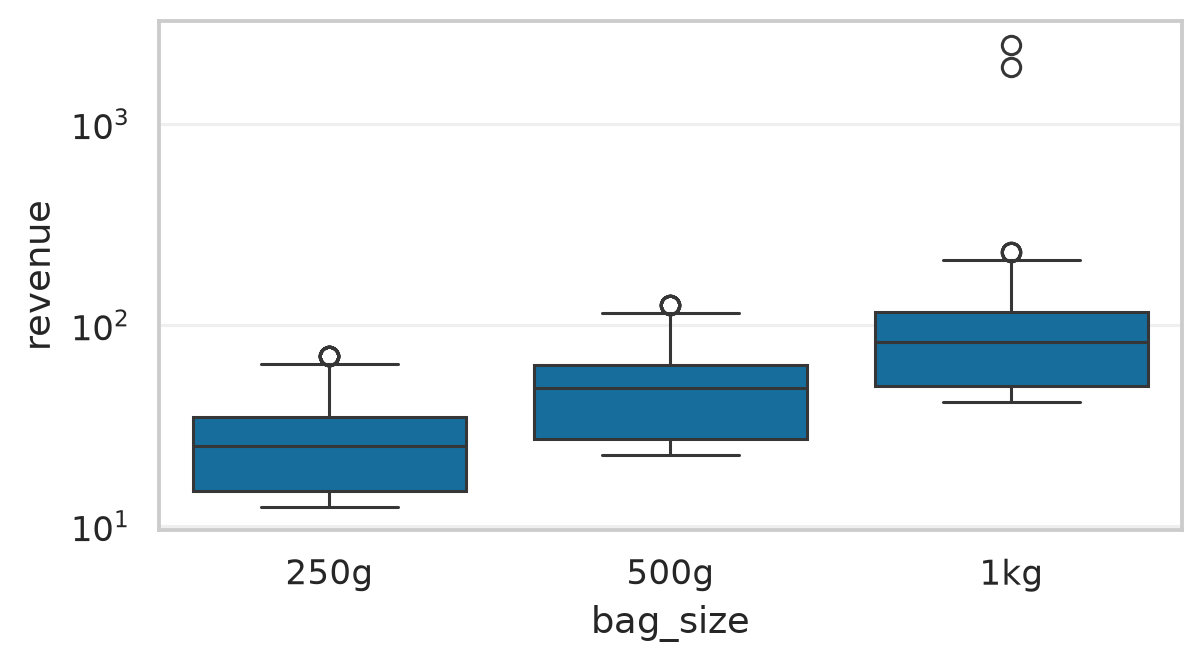

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.boxplot(data=orders, x="bag_size", y="revenue",
            order=["250g", "500g", "1kg"], ax=ax)
ax.set_yscale("log")
plt.show()

*Order revenue by bag size, on a log scale, as box plots.*

An order's revenue is the bag price times the number of bags, and most orders are for one or two bags, so each box covers a narrow range. The few points beyond the whiskers of the small bags are ordinary orders of four bags, which shows that a point in a box plot only means "far from the middle half", not "wrong". Far above the 1-kilogram box are the café's two wholesale orders, worth about $1,900 and $2,500; the log scale keeps them from squeezing everything else into the bottom of the chart.

## Exercise 16.3

*From Gapminder, draw a scatter chart of GDP per capita (log scale) against life expectancy for 1952 and 2007, side by side, colored by continent, with `relplot`.*

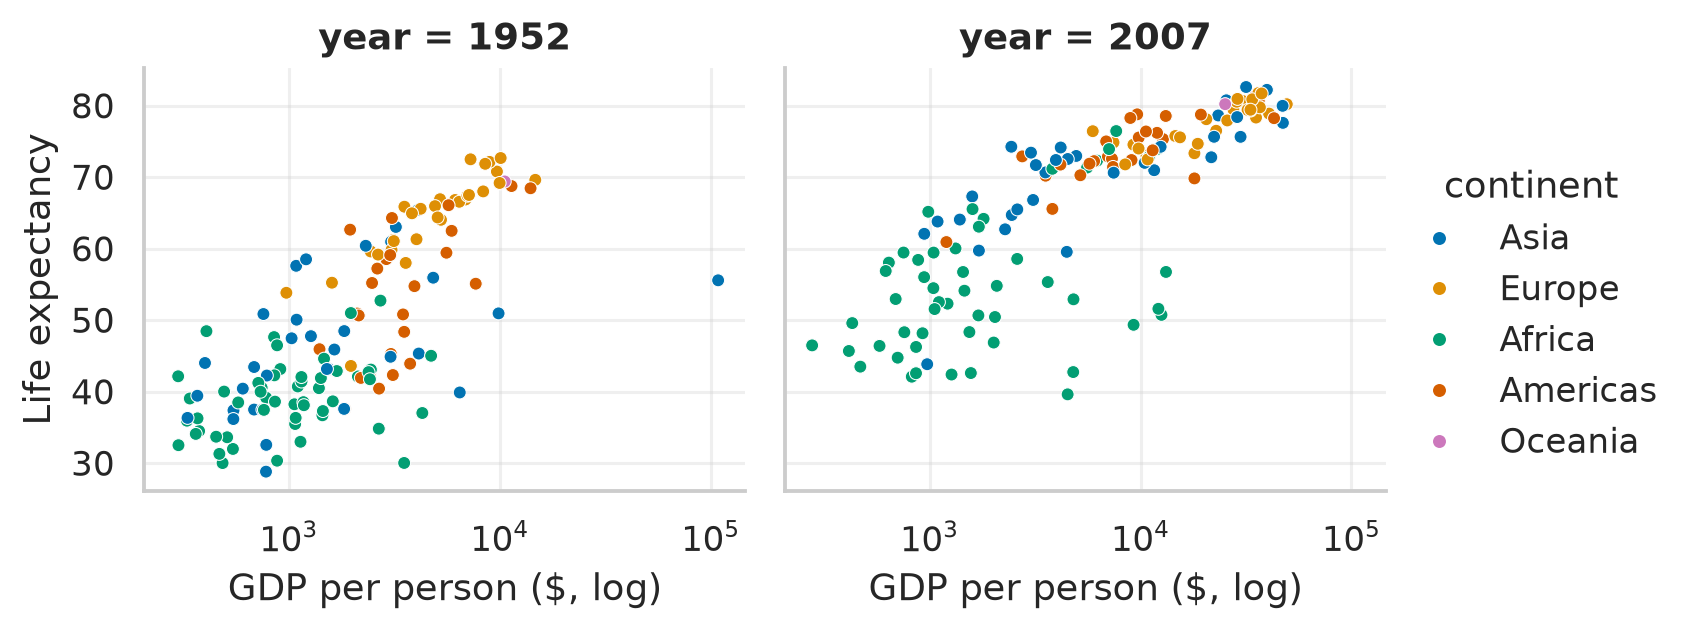

In [ ]:
two = gap[gap["year"].isin([1952, 2007])]
g = sns.relplot(data=two, x="gdpPercap", y="lifeExp", hue="continent",
                col="year", height=3, aspect=1.1, s=18)
g.set(xscale="log")
g.set_axis_labels("GDP per person ($, log)", "Life expectancy")
plt.show()

*Income and life expectancy in 1952 and 2007, one panel per year, on shared axes.*

`col="year"` puts the two years side by side on the same axes, and `g.set(xscale="log")` sets the scale on every panel. The whole cloud moved up and to the right, and in 2007 life expectancy was higher at every level of income than in 1952: richer countries live longer, but so does everyone at a given income.

## Exercise 16.4

*Draw a heatmap of the number of support tickets by weekday and hour of the day, New York time.*

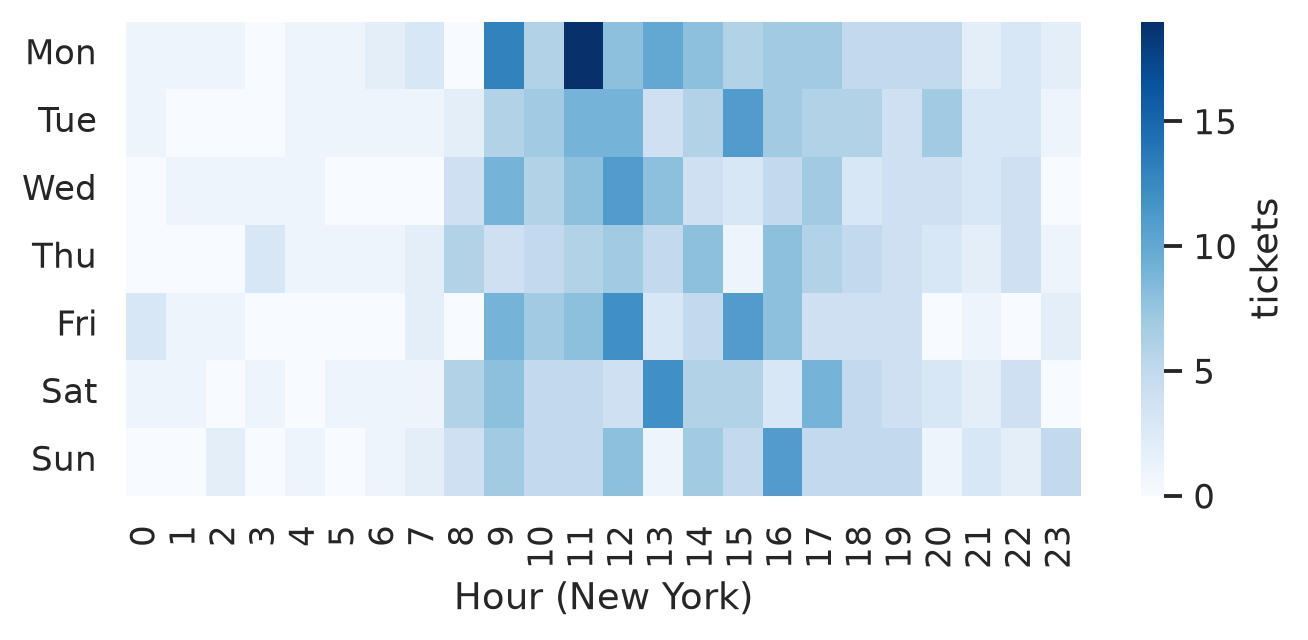

In [ ]:
raw = pd.read_csv("data/support_tickets.csv")
iso = raw["channel"].isin(["web", "phone"])
opened = pd.concat([
    pd.to_datetime(raw.loc[iso, "opened"], format="ISO8601", utc=True),
    pd.to_datetime(raw.loc[~iso, "opened"], format="%m/%d/%Y %I:%M %p")
    .dt.tz_localize("America/New_York").dt.tz_convert("UTC"),
]).sort_index().dt.tz_convert("America/New_York")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
grid = pd.crosstab(opened.dt.dayofweek.map(dict(enumerate(days))),
                   opened.dt.hour).reindex(days)
fig, ax = plt.subplots(figsize=(7, 2.8))
sns.heatmap(grid, cmap="Blues", cbar_kws={"label": "tickets"}, ax=ax)
ax.set_xlabel("Hour (New York)")
ax.set_ylabel("")
plt.show()

*Support tickets by weekday and hour of the day, New York time.*

The two formats are parsed as in Chapter 12 and combined with `concat`; `sort_index` puts them back in the original row order. `crosstab` counts tickets for each weekday and hour, and `reindex` puts the days in calendar order. The heatmap shows the working-day pattern: most tickets between 8 a.m. and 5 p.m., few at night, on every day of the week.

## Exercise 16.5

*With `catplot`, draw the mean rating by delivery days, one panel per bag size. Does the drop at six days appear for every size?*

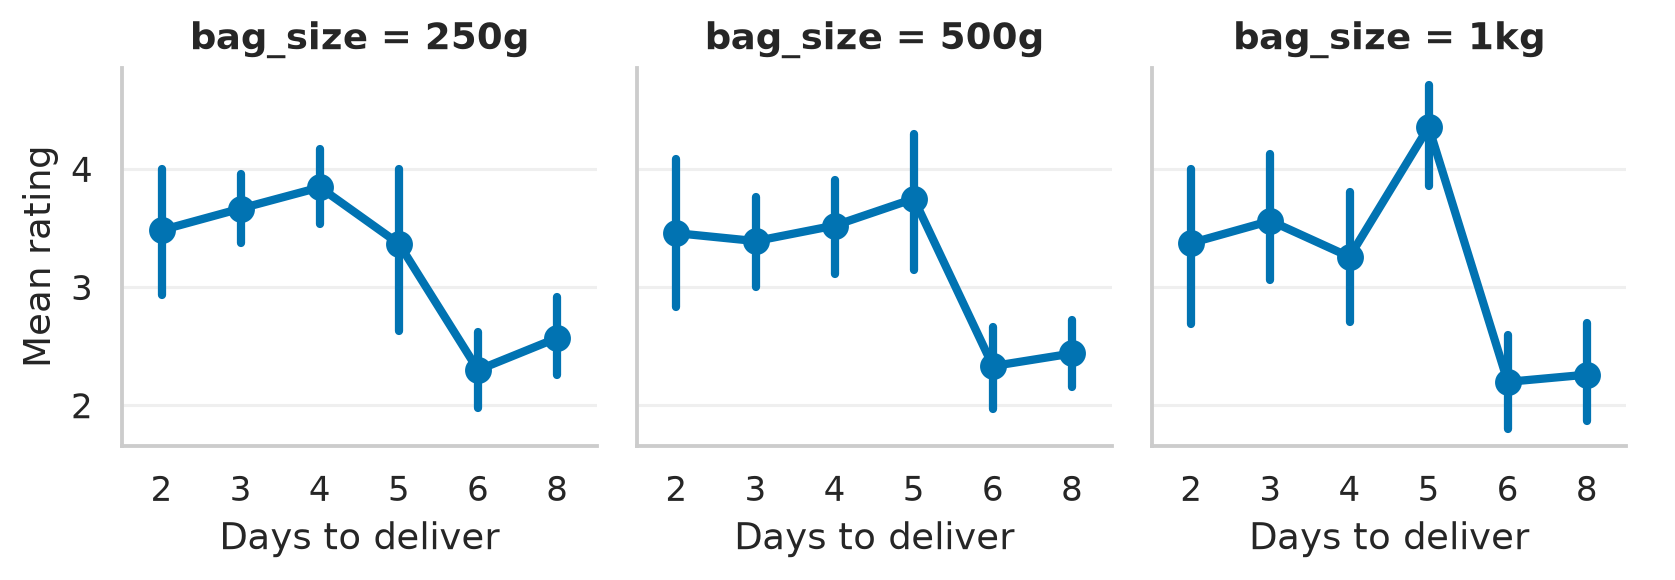

In [ ]:
rated = orders.dropna(subset=["rating", "shipping_days"]).astype(
    {"rating": float, "shipping_days": int})
g = sns.catplot(data=rated, x="shipping_days", y="rating",
                col="bag_size", col_order=["250g", "500g", "1kg"],
                kind="point", height=2.8, aspect=0.9)
g.set_axis_labels("Days to deliver", "Mean rating")
plt.show()

*Mean rating by delivery days, one panel per bag size, with 95% confidence intervals.*

Converting the nullable columns to plain `float` and `int` avoids surprises in seaborn's statistics. `kind="point"` draws each mean with its confidence interval. The drop between five and six days appears in all three panels, so slow delivery hurts ratings whatever the customer bought. The intervals are wide for the 1-kilogram bags, which have fewer rated orders.

## Exercise 16.6

*Redraw the bar chart of mean bill length by species and sex as a point plot. Which comparison does it make easier?*

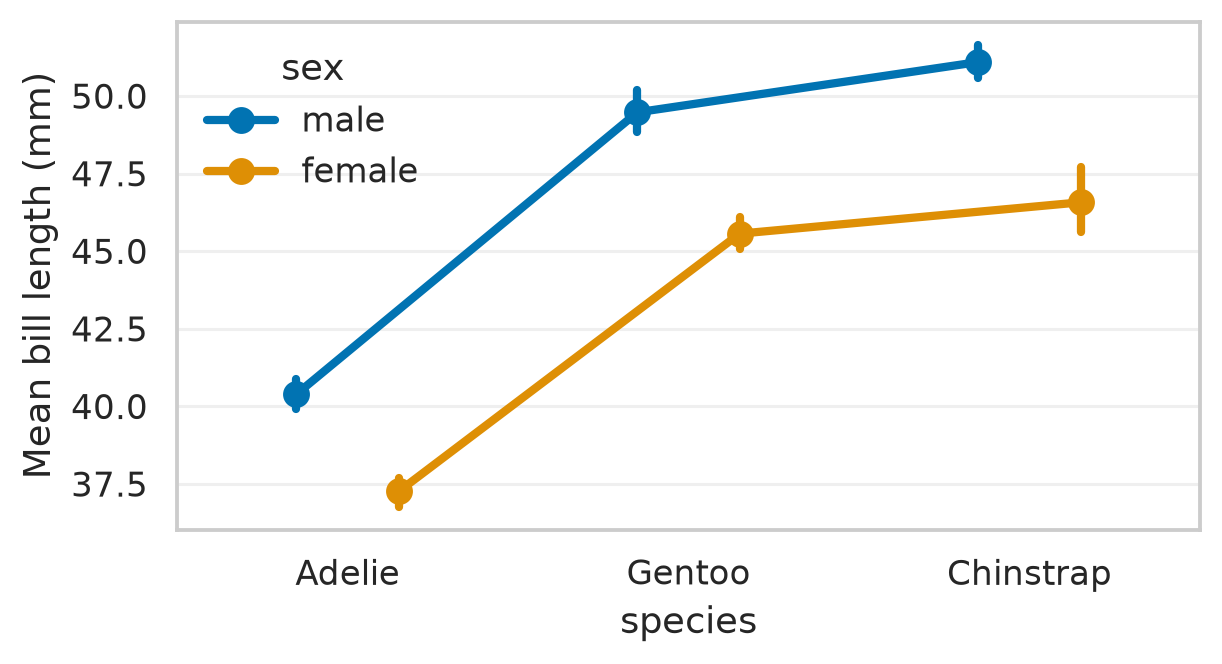

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.pointplot(data=penguins, x="species", y="bill_length_mm",
              hue="sex", dodge=0.3, ax=ax)
ax.set_ylabel("Mean bill length (mm)")
plt.show()

*Mean bill length by species and sex as a point plot, with confidence intervals.*

A point plot drops the bars, so the y axis doesn't have to start at zero, and the differences between the sexes, three to five millimeters, take up more of the chart. The lines connecting the points across species make it easy to see that the gap between the sexes is about the same in every species. Bars are better for showing amounts, points for comparing differences.

## Exercise 16.7

*Find another pair of penguin measurements whose overall correlation is much weaker, or of a different sign, than within the species, and show it with `lmplot`.*

In [ ]:
num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm",
       "body_mass_g"]
overall = penguins[num].corr()
within = penguins.groupby("species")[num].corr().groupby(level=1).mean()
diff = (within - overall).loc[num, num]
short = ["bill_len", "bill_dep", "flipper", "mass"]
print(diff.set_axis(short, axis=0).set_axis(short, axis=1).round(2))

          bill_len  bill_dep  flipper  mass
bill_len      0.00      0.80    -0.17 -0.02
bill_dep      0.80      0.00     1.12  1.11
flipper      -0.17      1.12     0.00 -0.27
mass         -0.02      1.11    -0.27  0.00


`groupby("species")[num].corr()` computes one correlation matrix per species, and averaging them over species gives the typical within-species correlation. Subtracting the overall matrix shows where the two disagree. Apart from bill length and depth, from the chapter, the largest difference is bill depth with flipper length and with body mass: strongly negative overall, but positive within each species.

overall r = -0.58


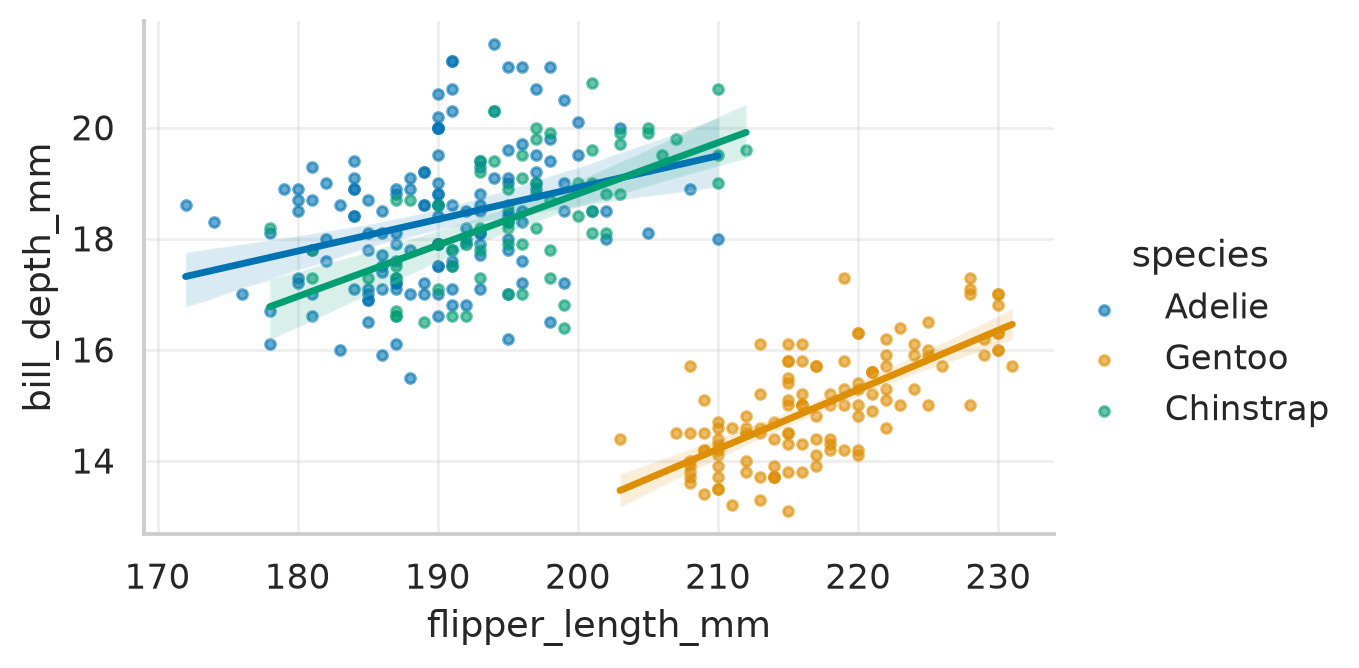

In [ ]:
g = sns.lmplot(data=penguins, x="flipper_length_mm",
               y="bill_depth_mm", hue="species", height=3.2,
               aspect=1.6, scatter_kws={"s": 10, "alpha": 0.6})
r = penguins["flipper_length_mm"].corr(penguins["bill_depth_mm"])
print(f"overall r = {r:.2f}")
plt.show()

*Flipper length against bill depth, with a regression line per species. Within each species, the lines slope upward.*

Overall, longer flippers go with shallower bills, an *r* of about -0.58, because Gentoos have the longest flippers and the shallowest bills. Within each species, birds with longer flippers have deeper bills, as bigger birds generally do. The overall correlation describes the difference between species, not a rule for individual birds.